# 01 — Data Exploration (ECtHR-NAACL2021)

Goal: understand the raw dataset **before** building the pipeline.
We check the structure, data quality, and the main distributions (time, countries, articles, document length),
and note what this means for indexing and search later.

Raw files: `data/train.jsonl`, `data/dev.jsonl`, `data/test.jsonl` (one JSON case per line).
Figures go to `report/figures/` so the report can use them.

In [1]:
import json, re
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

## 1. Load the three splits into one DataFrame

In [2]:
rows = []
for split in ["train", "dev", "test"]:
    with open(DATA / f"{split}.jsonl", encoding="utf-8") as f:
        for line in f:
            case = json.loads(line)
            case["split"] = split
            rows.append(case)

df = pd.DataFrame(rows)
df["judgment_date"] = pd.to_datetime(df["judgment_date"])
print(df.shape)
df["split"].value_counts()

(11000, 13)


split
train    9000
dev      1000
test     1000
Name: count, dtype: int64

## 2. Schema — what does one case look like?

In [3]:
df.dtypes

case_id                                object
case_no                                object
title                                  object
judgment_date                  datetime64[ns]
facts                                  object
applicants                             object
defendants                             object
allegedly_violated_articles            object
violated_articles                      object
court_assessment_references            object
silver_rationales                      object
gold_rationales                        object
split                                  object
dtype: object

In [4]:
example = df.iloc[0]
for col in df.columns:
    val = example[col]
    print(f"{col:30} {type(val).__name__:10} {str(val)[:110]}")

case_id                        str        001-59587
case_no                        str        25702/94
title                          str        CASE OF K. AND T. v. FINLAND
judgment_date                  Timestamp  2001-07-12 00:00:00
facts                          list       ['11.  At the beginning of the events relevant to the application, K. had a daughter, P., and a son, M., born 
applicants                     list       ['K.', 'T.']
defendants                     list       ['FINLAND']
allegedly_violated_articles    list       ['13', '8']
violated_articles              list       ['8']
court_assessment_references    dict       {'8': ['12', '140', '155', '156', '157', '158', '159', '160', '161', '162', '163', '164', '24', '32', '33', '3
silver_rationales              list       [1, 13, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 56]
gold_rationales                list       []
split                          str        train


In [5]:
# First two paragraphs of the facts, to see the raw text format
for p in example["facts"][:2]:
    print(p, "\n")

11.  At the beginning of the events relevant to the application, K. had a daughter, P., and a son, M., born in 1986 and 1988 respectively. P.’s father is X and M.’s father is V. From March to May 1989 K. was voluntarily hospitalised for about three months, having been diagnosed as suffering from schizophrenia. From August to November 1989 and from December 1989 to March 1990, she was again hospitalised for periods of about three months on account of this illness. In 1991 she was hospitalised for less than a week, diagnosed as suffering from an atypical and undefinable psychosis. It appears that social welfare and health authorities have been in contact with the family since 1989. 

12.  The applicants initially cohabited from the summer of 1991 to July 1993. In 1991 both P. and M. were living with them. From 1991 to 1993 K. and X were involved in a custody and access dispute concerning P. In May 1992 a residence order was made transferring custody of P. to X. 



**Field meaning**

| Field | Description |
|---|---|
| `case_id` / `case_no` | HUDOC identifier / application number |
| `title` | e.g. "CASE OF BECKER v. NORWAY" |
| `judgment_date` | date of the judgment |
| `facts` | list of paragraphs from the *Facts* section (the main searchable text) |
| `applicants` / `defendants` | parties (defendants = respondent states) |
| `allegedly_violated_articles` | ECHR articles the applicant claims were violated |
| `violated_articles` | articles the Court found violated (empty = no violation) |
| `court_assessment_references` | per article: which fact paragraphs the Court cites in its assessment |
| `silver_rationales` | indices of fact paragraphs cited by the Court (automatic labels) |
| `gold_rationales` | indices annotated by legal experts (only a few test cases) |

## 3. Data quality checks

In [6]:
list_cols = ["facts", "applicants", "defendants", "allegedly_violated_articles",
             "violated_articles", "silver_rationales", "gold_rationales"]

quality = pd.DataFrame({
    "empty lists": {c: (df[c].str.len() == 0).sum() for c in list_cols},
})
print("Duplicate case_id:", df["case_id"].duplicated().sum())
print("Duplicate title:  ", df["title"].duplicated().sum())
print("Null values:      ", int(df.isna().sum().sum()))
quality

Duplicate case_id: 0
Duplicate title:   187
Null values:       0


,empty lists
allegedly_violated_articles,46
applicants,2
defendants,19
facts,0
gold_rationales,10950
silver_rationales,5233
violated_articles,1045


In [7]:
# Paragraphs keep their original numbering ("11.  K. had a daughter...") -> must be stripped in the pipeline
paras = df["facts"].explode()
numbered = paras.str.match(r"^\d+\.\s").mean()
print(f"Paragraphs starting with a number: {numbered:.2%}")
print("Empty paragraphs:", (paras.str.strip() == "").sum())

Paragraphs starting with a number: 100.00%
Empty paragraphs: 0


In [8]:
# Label consistency
alleged = df["allegedly_violated_articles"].apply(set)
violated = df["violated_articles"].apply(set)
print("Cases with no alleged article:          ", (alleged.str.len() == 0).sum())
print("Cases with violated ⊄ alleged:          ", sum(bool(v - a) for v, a in zip(violated, alleged)))
print("Cases with silver index out of range:   ",
      sum(bool(s) and max(s) >= len(f) for s, f in zip(df["silver_rationales"], df["facts"])))

Cases with no alleged article:           46
Cases with violated ⊄ alleged:           254
Cases with silver index out of range:    0


In [9]:
# Duplicate titles are usually different cases against the same state with the same applicant name
df[df["title"].duplicated(keep=False)].sort_values("title")[["case_id", "title", "judgment_date"]].head(10)

,case_id,title,judgment_date
6900,001-111553,CASE OF A.A. AND OTHERS v. SWEDEN,2012-06-28
8194,001-145789,CASE OF A.A. AND OTHERS v. SWEDEN,2014-07-24
9835,001-174400,CASE OF AKGÜL v. TURKEY,2017-06-13
2402,001-79008,CASE OF AKGÜL v. TURKEY,2007-01-16
5172,001-97980,CASE OF ALLEN v. THE UNITED KINGDOM,2010-03-30
7569,001-122859,CASE OF ALLEN v. THE UNITED KINGDOM,2013-07-12
7883,001-140244,CASE OF ALVES v. PORTUGAL,2014-01-28
8593,001-154344,CASE OF ALVES v. PORTUGAL,2015-04-30
10025,001-177670,CASE OF AMIROV v. RUSSIA,2017-10-17
8353,001-148225,CASE OF AMIROV v. RUSSIA,2014-11-27


## 4. Derived columns used for the analysis

In [10]:
df["year"] = df["judgment_date"].dt.year
df["n_paragraphs"] = df["facts"].str.len()
df["n_words"] = df["facts"].apply(lambda ps: sum(len(p.split()) for p in ps))
df["n_alleged"] = df["allegedly_violated_articles"].str.len()
df["n_violated"] = df["violated_articles"].str.len()
df["outcome"] = df["n_violated"].map(lambda n: "violation" if n > 0 else "no violation")
df["n_silver"] = df["silver_rationales"].str.len()
df[["n_paragraphs", "n_words", "n_alleged", "n_violated", "n_silver"]].describe().round(1)

,n_paragraphs,n_words,n_alleged,n_violated,n_silver
count,11000.0,11000.0,11000.0,11000.0,11000.0
mean,23.9,1662.1,1.8,1.3,3.8
std,22.8,1967.6,1.1,0.8,7.5
min,1.0,69.0,0.0,0.0,0.0
25%,11.0,505.0,1.0,1.0,0.0
50%,17.0,1032.5,2.0,1.0,1.0
75%,29.0,2069.2,2.0,2.0,5.0
max,558.0,35416.0,10.0,8.0,138.0


## 5. Splits and time

In [11]:
summary = df.groupby("split", sort=False).agg(
    cases=("case_id", "size"),
    first=("judgment_date", "min"),
    last=("judgment_date", "max"),
    median_words=("n_words", "median"),
    no_violation=("outcome", lambda s: (s == "no violation").sum()),
    with_gold=("gold_rationales", lambda s: (s.str.len() > 0).sum()),
)
summary

,cases,first,last,median_words,no_violation,with_gold
split,,,,,,
train,9000,2001-07-12,2016-02-09,984.0,762,0
dev,1000,2016-02-09,2017-10-05,1255.0,148,0
test,1000,2017-10-05,2019-07-02,1412.5,135,50


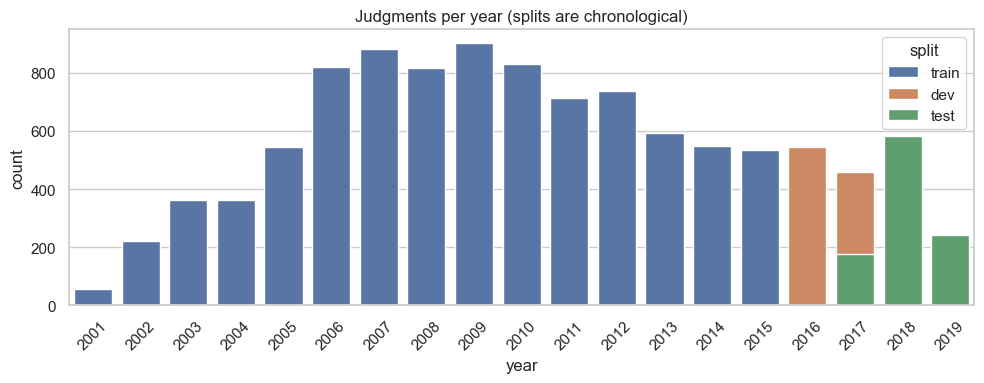

In [12]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="year", hue="split", dodge=False)
plt.title("Judgments per year (splits are chronological)")
plt.xticks(rotation=45)
savefig("cases_per_year")

## 6. Respondent states (defendants)

Distinct states: 47
Cases with >1 respondent state: 47


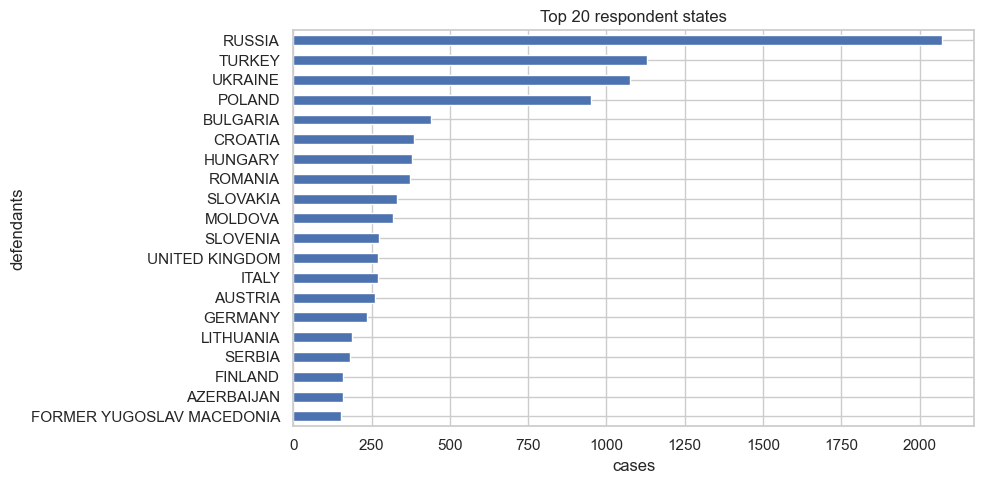

In [13]:
countries = df["defendants"].explode().value_counts()
print("Distinct states:", countries.size)
print("Cases with >1 respondent state:", (df["defendants"].str.len() > 1).sum())
plt.figure(figsize=(10, 5))
countries.head(20).plot.barh().invert_yaxis()
plt.title("Top 20 respondent states")
plt.xlabel("cases")
savefig("top_countries")

In [14]:
# Violation rate per country (countries with >= 100 cases)
by_country = df.explode("defendants").groupby("defendants").agg(
    cases=("case_id", "size"),
    violation_rate=("outcome", lambda s: (s == "violation").mean()),
)
by_country[by_country["cases"] >= 100].sort_values("violation_rate").round(3)

,cases,violation_rate
defendants,,
FRANCE,112,0.589
GERMANY,235,0.634
UNITED KINGDOM,272,0.706
LITHUANIA,186,0.758
AUSTRIA,260,0.777
LATVIA,105,0.800
FINLAND,160,0.812
CROATIA,385,0.875
POLAND,951,0.896


In [15]:
# Number of applicants (note: names like "K. AND T." are split into several applicants)
df["applicants"].str.len().value_counts()

applicants
1    8963
2    2002
3      31
4       2
0       2
Name: count, dtype: int64

## 7. ECHR articles — alleged vs. violated

In [16]:
alleged_counts = df["allegedly_violated_articles"].explode().value_counts()
violated_counts = df["violated_articles"].explode().value_counts()
articles = pd.DataFrame({"alleged": alleged_counts, "violated": violated_counts}).fillna(0).astype(int)
articles["violation_rate"] = (articles["violated"] / articles["alleged"]).round(3)
articles = articles.sort_values("alleged", ascending=False)
print("Distinct articles alleged:", alleged_counts.size, "| violated:", violated_counts.size)
articles.head(20)

Distinct articles alleged: 33 | violated: 29


,alleged,violated,violation_rate
6,6225,5303,0.852
3,2210,1731,0.783
5,2038,1721,0.844
13,1900,1405,0.739
P1-1,1881,1682,0.894
8,1397,920,0.659
2,774,618,0.798
34,660,112,0.170
10,611,410,0.671
14,510,175,0.343


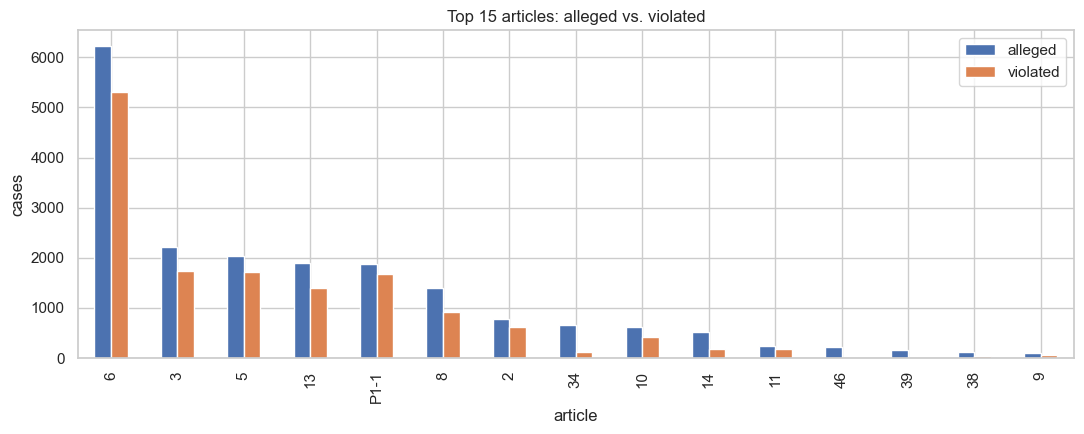

In [17]:
top = articles.head(15)
ax = top[["alleged", "violated"]].plot.bar(figsize=(11, 4.5))
ax.set_title("Top 15 articles: alleged vs. violated")
ax.set_xlabel("article")
ax.set_ylabel("cases")
savefig("articles_alleged_vs_violated")

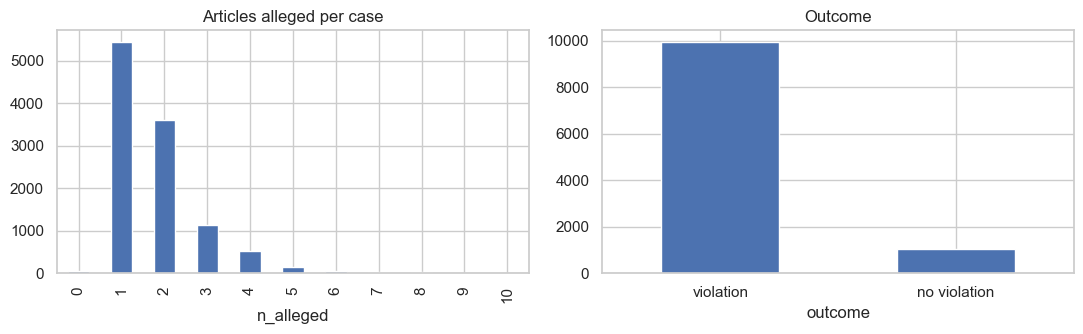

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["n_alleged"].value_counts().sort_index().plot.bar(ax=axes[0], title="Articles alleged per case")
df["outcome"].value_counts().plot.bar(ax=axes[1], title="Outcome")
axes[1].tick_params(axis="x", rotation=0)
savefig("labels_per_case")

In [19]:
# Which articles are alleged together? (top pairs)
pairs = Counter()
for arts in df["allegedly_violated_articles"]:
    arts = sorted(set(arts))
    pairs.update((a, b) for i, a in enumerate(arts) for b in arts[i + 1:])
pd.DataFrame(pairs.most_common(10), columns=["pair", "cases"])

,pair,cases
0,"(6, P1-1)",1290
1,"(13, 6)",1108
2,"(3, 5)",797
3,"(13, 3)",701
4,"(5, 6)",570
5,"(3, 6)",547
6,"(13, 5)",422
7,"(6, 8)",401
8,"(2, 3)",367
9,"(13, 2)",366


## 8. Document length

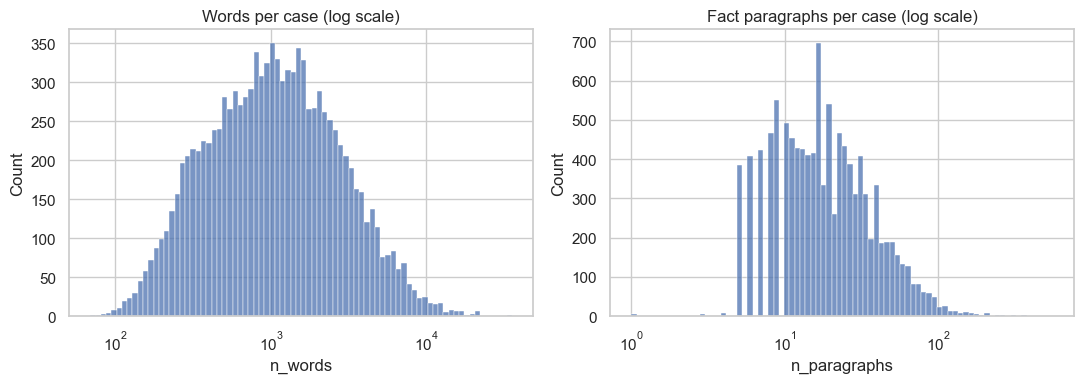

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["n_words"], bins=80, log_scale=True, ax=axes[0])
axes[0].set_title("Words per case (log scale)")
sns.histplot(df["n_paragraphs"], bins=80, log_scale=True, ax=axes[1])
axes[1].set_title("Fact paragraphs per case (log scale)")
savefig("document_length")

In [21]:
para_words = paras.str.split().str.len()
print(para_words.describe().round(1))
print("\nLongest cases:")
df.nlargest(5, "n_words")[["title", "year", "n_paragraphs", "n_words"]]

count    262580.0
mean         69.6
std          97.5
min           4.0
25%          27.0
50%          47.0
75%          82.0
max        8971.0
Name: facts, dtype: float64

Longest cases:


,title,year,n_paragraphs,n_words
588,CASE OF ELÇI AND OTHERS v. TURKEY,2003,558,35416
7600,CASE OF KHODORKOVSKIY AND LEBEDEV v. RUSSIA,2013,370,33726
8750,CASE OF KAVAKLIOĞLU AND OTHERS v. TURKEY,2015,138,21911
6273,CASE OF OAO NEFTYANAYA KOMPANIYA YUKOS v. RUSSIA,2011,301,21836
1122,CASE OF SHAMAYEV AND OTHERS v. GEORGIA AND RUSSIA,2005,201,21799


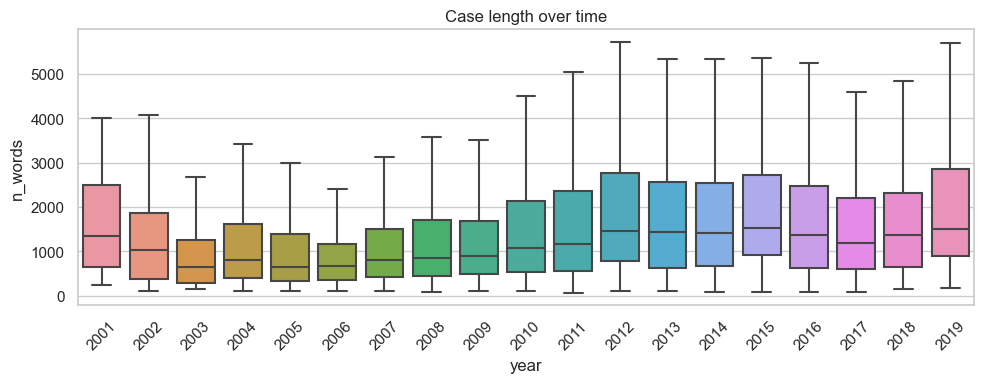

In [22]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="year", y="n_words", showfliers=False)
plt.title("Case length over time")
plt.xticks(rotation=45)
savefig("length_over_time")

## 9. Rationales (paragraphs the Court relied on)

In [23]:
has_silver = df["n_silver"] > 0
print(f"Cases with silver rationales: {has_silver.sum()} ({has_silver.mean():.1%})")
print("Silver rationales by outcome:")
print(df.groupby("outcome")["n_silver"].apply(lambda s: (s > 0).mean()).round(3))
coverage = (df.loc[has_silver, "n_silver"] / df.loc[has_silver, "n_paragraphs"])
print(f"\nShare of facts marked as rationale (median): {coverage.median():.1%}")

Cases with silver rationales: 5767 (52.4%)
Silver rationales by outcome:
outcome
no violation    0.643
violation       0.512
Name: n_silver, dtype: float64

Share of facts marked as rationale (median): 20.0%


In [24]:
# One gold example: show the rationale paragraphs
g = df[df["gold_rationales"].str.len() > 0].iloc[0]
print(g["title"], "| violated:", g["violated_articles"])
for i in g["gold_rationales"][:3]:
    print(f"[{i}]", g["facts"][i][:300], "\n")

CASE OF GÜLER AND TEKDAL v. TURKEY | violated: ['2']
[4] 9.  Between 5 and 7 p.m. the same day, villagers in Ecemiş village heard gunfire. The following day the headman of the village (“muhtar”) was informed that a person had been killed. The headman, accompanied by 20‑30 villagers, went to Lice, where he was handed the body of the applicants’ relative, M 

[5] 10.  According to a report drawn up on 13 September 2008 by seven members of the military, a military operation was being carried out in the area near the applicants’ village on 12 September 2008 when at 11.15 p.m. soldiers encountered 3-4 persons in the area whom they considered to be members of th 

[6] 11.  At 5 a.m. the following morning the soldiers conducted a search in the area and noticed the footsteps of four persons. The footsteps disappeared some two kilometres away, next to a little brook in a valley. At that location the soldiers also found supplies of food. The soldiers continued their  



## 10. Vocabulary — first look at the text

In [25]:
STOP = set("""the of and to in a on that was he his by with for as is at from had which be
it an this not were her she they their been by its or has have are also would
s i him who 1 2 3 4 5 6 7 8 9 10 under into no after did there than these""".split())

tokens = Counter()
for p in paras:
    tokens.update(t for t in re.findall(r"[a-z]+", p.lower()) if t not in STOP and len(t) > 2)
print("Vocabulary size:", len(tokens))
pd.DataFrame(tokens.most_common(30), columns=["term", "freq"]).T

Vocabulary size: 82126


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
term,applicant,court,case,decision,appeal,proceedings,police,district,against,prosecutor,...,detention,november,office,february,july,september,article,january,any,regional
freq,296537,211689,50754,49057,48476,47776,44727,44121,42106,42076,...,30176,29658,29180,28559,28398,27843,27762,27403,27193,26957


In [26]:
# Distinctive terms per top article (term frequency in cases alleging that article vs. all cases)
def top_terms(mask, n=12):
    c = Counter()
    for ps in df.loc[mask, "facts"]:
        c.update(t for p in ps for t in re.findall(r"[a-z]+", p.lower()) if t not in STOP and len(t) > 2)
    total = sum(c.values())
    base = sum(tokens.values())
    score = {t: (f / total) / (tokens[t] / base) for t, f in c.items() if f > 1000 and tokens[t] > 3000}
    return [t for t, _ in sorted(score.items(), key=lambda x: -x[1])[:n]]

for art in ["3", "5", "6", "8", "10", "P1-1"]:
    mask = df["allegedly_violated_articles"].apply(lambda a: art in a)
    print(f"Art. {art:5}", ", ".join(top_terms(mask)))

Art. 3     cells, inmates, cell, detainees, abduction, facility, servicemen, men, injuries, investigators, relatives, treatment
Art. 5     abduction, servicemen, extended, detention, release, investigators, men, released, armed, detained, remand, measure
Art. 6     adjourned, hearings, defendant, hearing, remitted, awarded, payment, scheduled, judgments, claims, company, claim
Art. 8     child, contact, children, parents, father, mother, care, residence, family, return, school, living
Art. 10    people, public, party, article, information, statements, company, such, statement, fact, section, question
Art. P1-1  plot, land, property, bank, awarded, paid, eur, possession, payment, compensation, flat, enforcement


## 11. Findings → decisions for the next steps

**Data quality**
- No duplicate IDs, no nulls, no empty facts → the dataset is clean.
- ~100% of paragraphs start with their original number (`"11.  ..."`) → strip it in the pipeline.
- 46 cases have no alleged article, 254 have violated articles missing from the alleged list, 19 have no defendant → keep, but handle empty values.
- Applicant names are sometimes split on "AND" (e.g. "K. AND T.") → don't rely on `applicants` for counts.

**Distributions**
- Splits are chronological (train 2001–2016, dev 2016–2017, test 2017–2019); the search system indexes all 11k cases.
- 47 states; Russia alone is ~19% of cases, followed by Turkey, Ukraine, Poland → useful facet, but the collection is skewed.
- 187 duplicate titles are distinct cases (same parties, different years) → always use `case_id` as the key.
- 33 distinct articles; Art. 6 is alleged in 57% of cases, and ~90% of cases end in a violation → strong class imbalance for any ML component.
- Some articles (34, 46, 39) are almost never found violated → they are procedural, not substantive.
- Lengths vary widely (log-normal, some cases > 30k words) → consider paragraph-level indexing / snippets.
- ~52% of cases have silver rationales (more often no-violation cases: 64% vs 51%); when present they mark ~20% of the facts → optional "key paragraphs" field.